In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
df = load_breast_cancer(as_frame=True).frame
df.shape

(569, 31)

In [4]:
df.sample(5)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
41,10.95,21.35,71.90,371.1,0.12270,0.12180,0.10440,0.05669,0.1895,0.06870,...,35.34,87.22,514.0,0.1909,0.2698,0.40230,0.14240,0.2964,0.09606,0
262,17.29,22.13,114.40,947.8,0.08999,0.12730,0.09697,0.07507,0.2108,0.05464,...,27.24,137.90,1295.0,0.1134,0.2867,0.22980,0.15280,0.3067,0.07484,0
53,18.22,18.70,120.30,1033.0,0.11480,0.14850,0.17720,0.10600,0.2092,0.06310,...,24.13,135.10,1321.0,0.1280,0.2297,0.26230,0.13250,0.3021,0.07987,0
513,14.58,13.66,94.29,658.8,0.09832,0.08918,0.08222,0.04349,0.1739,0.05640,...,17.24,108.50,862.0,0.1223,0.1928,0.24920,0.09186,0.2626,0.07048,1
436,12.87,19.54,82.67,509.2,0.09136,0.07883,0.01797,0.02090,0.1861,0.06347,...,24.38,95.14,626.9,0.1214,0.1652,0.07127,0.06384,0.3313,0.07735,1


In [3]:
X = df.drop('target',axis=1)
y = df['target']

In [6]:
scaler = StandardScaler()

x_scaled = scaler.fit_transform(X)

In [8]:
from sklearn.decomposition import PCA

np.set_printoptions(suppress=True);

pca_full = PCA(n_components=None); # pca for all columns

pca_full.fit_transform(x_scaled)

explained = pca_full.explained_variance_ratio_
explained

array([0.44272026, 0.18971182, 0.09393163, 0.06602135, 0.05495768,
       0.04024522, 0.02250734, 0.01588724, 0.01389649, 0.01168978,
       0.00979719, 0.00870538, 0.00804525, 0.00523366, 0.00313783,
       0.00266209, 0.00197997, 0.00175396, 0.00164925, 0.00103865,
       0.0009991 , 0.00091465, 0.00081136, 0.00060183, 0.00051604,
       0.00027259, 0.00023002, 0.00005298, 0.00002496, 0.00000443])

In [9]:
cumulative_variance = np.cumsum(explained)
cumulative_variance # prefix sum

array([0.44272026, 0.63243208, 0.72636371, 0.79238506, 0.84734274,
       0.88758796, 0.9100953 , 0.92598254, 0.93987903, 0.95156881,
       0.961366  , 0.97007138, 0.97811663, 0.98335029, 0.98648812,
       0.98915022, 0.99113018, 0.99288414, 0.9945334 , 0.99557204,
       0.99657114, 0.99748579, 0.99829715, 0.99889898, 0.99941502,
       0.99968761, 0.99991763, 0.99997061, 0.99999557, 1.        ])

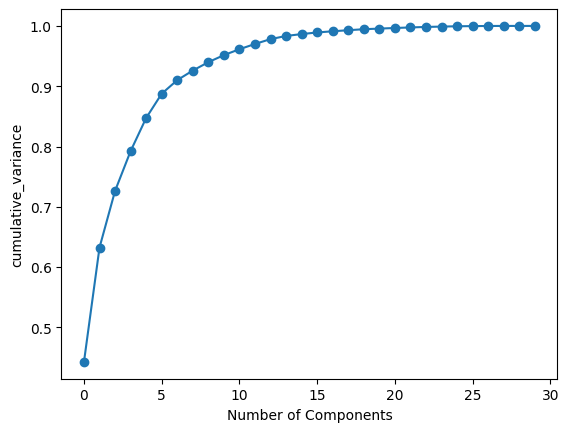

In [10]:
plt.plot(cumulative_variance,marker='o');
plt.xlabel("Number of Components");
plt.ylabel("cumulative_variance")
plt.show()

Comparing a model's accuracy with and without pca

In [11]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [12]:
x_train, x_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y);

# Pipeline WITHOUT PCA: Scale -> Logistic Regression
pipe_no_pca = Pipeline(
    steps=[
        ("scaler",StandardScaler()),
        ("clf",LogisticRegression(max_iter=500))
    ]
)

pipe_no_pca.fit(x_train,y_train);
predicted_no_pca = pipe_no_pca.predict(x_test);
acc_no_pca = accuracy_score(y_test, predicted_no_pca);

In [13]:
print("Accuracy (No PCA):", acc_no_pca)

Accuracy (No PCA): 0.9824561403508771


In [15]:
#? Pipeline with PCA: Scale 
pipe_with_pca = Pipeline(
    steps=[
        ("scaler",StandardScaler()),
        ("pca",PCA(n_components=10)),
        ("clf",LogisticRegression(max_iter=500))
    ]
)

pipe_with_pca.fit(x_train,y_train);
predicted_with_pca = pipe_with_pca.predict(x_test);
acc_with_pca = accuracy_score(y_test, predicted_with_pca);
print("Accuracy (with PCA):", acc_with_pca)

Accuracy (with PCA): 0.9736842105263158



### Explaination of the Results

If PCA accuracy is similar:
- Great. We reduced dimensions without losing performance.

If PCA accuracy is better:
- PCA likely removed redundancy/noise that was confusing the model.

If PCA accuracy is worse:
- We removed useful information.
- Increase the threshold (for example, 0.98), or skip PCA.

Bottom line:
PCA is a tool. Use it when it matches the problem conditions.
